<a href="https://colab.research.google.com/github/Shreyas408315/Gen-AI/blob/main/Next_Word_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Selected device:", device)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
NumPy: 2.1.3
GPU available: True
Selected device: cuda


In [ ]:

import urllib.request

url = (
    "https://www.gutenberg.org/cache/epub/11/pg11.txt"
)

try:
    with urllib.request.urlopen(url, timeout=30) as response:
        text_data = response.read().decode("utf-8")

    print("Dataset loaded successfully!")
    print("Characters:", len(text_data))
    print("\nFirst 500 characters:\n")
    print(text_data[:500])

except Exception as e:
    print("Download failed:", e)
    print("We can use an alternative dataset-loading method.")


Dataset loaded successfully!
Characters: 167712

First 500 characters:

The Project Gutenberg eBook of Alice's Adventures in Wonderland
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
befor


In [ ]:

import re

start_marker = "*** START OF"
end_marker = "*** END OF"

start = text_data.find(start_marker)
end = text_data.find(end_marker)

if start != -1:
    newline = text_data.find("\n", start)
    text_data = text_data[newline + 1:]

if end != -1:
    text_data = text_data[:text_data.find(end_marker)]
clean_text = text_data.lower()
clean_text = re.sub(r"\s+", " ", clean_text).strip()

print("Cleaned characters:", len(clean_text))
print("\nSample:")
print(clean_text[:500])


Cleaned characters: 143127

Sample:
[illustration] alice’s adventures in wonderland by lewis carroll the millennium fulcrum edition 3.0 contents chapter i. down the rabbit-hole chapter ii. the pool of tears chapter iii. a caucus-race and a long tale chapter iv. the rabbit sends in a little bill chapter v. advice from a caterpillar chapter vi. pig and pepper chapter vii. a mad tea-party chapter viii. the queen’s croquet-ground chapter ix. the mock turtle’s story chapter x. the lobster quadrille chapter xi. who stole the tarts? chap


In [ ]:

tokens = re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]", clean_text)

print("Total tokens:", len(tokens))
print("First 40 tokens:")
print(tokens[:40])


Total tokens: 35507
First 40 tokens:
['[', 'illustration', ']', 'alice', '’', 's', 'adventures', 'in', 'wonderland', 'by', 'lewis', 'carroll', 'the', 'millennium', 'fulcrum', 'edition', '3', '.', '0', 'contents', 'chapter', 'i', '.', 'down', 'the', 'rabbit', '-', 'hole', 'chapter', 'ii', '.', 'the', 'pool', 'of', 'tears', 'chapter', 'iii', '.', 'a', 'caucus']


In [ ]:

n = len(tokens)

train_end = int(n * 0.80)
val_end = int(n * 0.90)

train_tokens = tokens[:train_end]
val_tokens = tokens[train_end:val_end]
test_tokens = tokens[val_end:]

print("Training tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))
print("Test tokens:", len(test_tokens))


Training tokens: 28405
Validation tokens: 3551
Test tokens: 3551


In [ ]:

from collections import Counter

PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

word_counts = Counter(train_tokens)

# Reserve IDs 0 and 1
vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, count in word_counts.most_common():
    if word not in vocab:
        vocab[word] = len(vocab)

id_to_word = {idx: word for word, idx in vocab.items()}

vocab_size = len(vocab)

print("Vocabulary size:", vocab_size)
print("\nMost common tokens:")
print(word_counts.most_common(15))

print("\nExample token IDs:")
for word in ["alice", "was", "the", "rabbit", "."]:
    print(f"{word}: {vocab.get(word, vocab[UNK_TOKEN])}")


Vocabulary size: 2307

Most common tokens:
[(',', 1925), ('the', 1209), ('“', 861), ('”', 859), ('.', 765), ('and', 713), ('to', 615), ('’', 579), ('a', 534), ('it', 505), ('she', 470), ('i', 464), ('of', 384), ('!', 383), ('said', 347)]

Example token IDs:
alice: 18
was: 19
the: 3
rabbit: 124
.: 6


In [ ]:

def encode_tokens(token_list, vocab):
    unk_id = vocab[UNK_TOKEN]
    return [vocab.get(token, unk_id) for token in token_list]
train_ids = encode_tokens(train_tokens, vocab)
val_ids = encode_tokens(val_tokens, vocab)
test_ids = encode_tokens(test_tokens, vocab)
print("Training IDs:", train_ids[:20])
print("Validation IDs:", val_ids[:20])
print("Test IDs:", test_ids[:20])
sample_ids = train_ids[:10]
print("\nDecoded sample:")
print([id_to_word[i] for i in sample_ids])


Training IDs: [1294, 1295, 1296, 18, 9, 30, 1297, 20, 1298, 93, 1299, 1300, 3, 1301, 1302, 1303, 1304, 6, 1305, 1306]
Validation IDs: [3, 139, 2, 4, 21, 42, 76, 113, 35, 3, 523, 8, 3, 295, 6, 40, 42, 129, 1, 47]
Test IDs: [5, 53, 97, 6, 4, 17, 9, 141, 10, 38, 194, 1, 2, 5, 16, 3, 234, 6, 95, 52]

Decoded sample:
['[', 'illustration', ']', 'alice', '’', 's', 'adventures', 'in', 'wonderland', 'by']


In [ ]:

import torch
from torch.utils.data import Dataset, DataLoader

SEQ_LEN = 20
BATCH_SIZE = 64

class NextWordDataset(Dataset):
    def __init__(self, token_ids, seq_len):
        self.data = torch.tensor(token_ids, dtype=torch.long)
        self.seq_len = seq_len

    def __len__(self):
        return max(0, len(self.data) - self.seq_len)

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.seq_len]
        y = self.data[idx + self.seq_len]
        return x, y

train_dataset = NextWordDataset(train_ids, SEQ_LEN)
val_dataset = NextWordDataset(val_ids, SEQ_LEN)
test_dataset = NextWordDataset(test_ids, SEQ_LEN)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))


Training examples: 28385
Validation examples: 3531
Test examples: 3531


In [ ]:

x, y = train_dataset[0]

print("Input IDs:", x.tolist())
print("Input words:", [id_to_word[i] for i in x.tolist()])
print("Target ID:", y.item())
print("Target word:", id_to_word[y.item()])


Input IDs: [1294, 1295, 1296, 18, 9, 30, 1297, 20, 1298, 93, 1299, 1300, 3, 1301, 1302, 1303, 1304, 6, 1305, 1306]
Input words: ['[', 'illustration', ']', 'alice', '’', 's', 'adventures', 'in', 'wonderland', 'by', 'lewis', 'carroll', 'the', 'millennium', 'fulcrum', 'edition', '3', '.', '0', 'contents']
Target ID: 183
Target word: chapter


In [ ]:

import torch.nn as nn

EMBED_DIM = 128
HIDDEN_DIM = 128

class NextWordModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        hidden_dim=128,
        model_type="RNN"
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim
        )

        if model_type == "RNN":
            self.recurrent = nn.RNN(
                input_size=embed_dim,
                hidden_size=hidden_dim,
                batch_first=True
            )
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size=embed_dim,
                hidden_size=hidden_dim,
                batch_first=True
            )
        elif model_type == "GRU":
            self.recurrent = nn.GRU(
                input_size=embed_dim,
                hidden_size=hidden_dim,
                batch_first=True
            )
        else:
            raise ValueError("Use RNN, LSTM, or GRU")

        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)

        output, hidden = self.recurrent(embedded)
        last_output = output[:, -1, :]

        logits = self.fc(last_output)
        return logits
rnn_model = NextWordModel(
    vocab_size=vocab_size,
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    model_type="RNN"
).to(device)

print(rnn_model)

total_params = sum(
    p.numel() for p in rnn_model.parameters()
    if p.requires_grad
)
print("Trainable parameters:", total_params)


NextWordModel(
  (embedding): Embedding(2307, 128)
  (recurrent): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=2307, bias=True)
)
Trainable parameters: 625923


In [ ]:

sample_x, sample_y = next(iter(train_loader))
sample_x = sample_x.to(device)

with torch.no_grad():
    sample_logits = rnn_model(sample_x)

print("Input shape:", sample_x.shape)
print("Logits shape:", sample_logits.shape)
print("Target shape:", sample_y.shape)

assert sample_logits.shape == (
    sample_x.shape[0], vocab_size
)

print("Forward pass successful!")


Input shape: torch.Size([64, 20])
Logits shape: torch.Size([64, 2307])
Target shape: torch.Size([64])
Forward pass successful!


In [ ]:

import math
import time

criterion = nn.CrossEntropyLoss()

def evaluate_model(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            batch_size = y.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (
                logits.argmax(dim=1) == y
            ).sum().item()
            total_examples += batch_size

    avg_loss = total_loss / total_examples
    accuracy = total_correct / total_examples
    perplexity = math.exp(min(avg_loss, 20))

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "perplexity": perplexity
    }


def train_model(model, train_loader, val_loader,
                epochs=5, learning_rate=0.001):

    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_perplexity": []
    }

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_examples = 0
        start_time = time.time()

        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            logits = model(x)
            loss = criterion(logits, y)

            loss.backward()

            # Prevent excessively large gradients
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            batch_size = y.size(0)
            total_loss += loss.item() * batch_size
            total_examples += batch_size

        train_loss = total_loss / total_examples
        val_metrics = evaluate_model(
            model, val_loader
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(
            val_metrics["accuracy"]
        )
        history["val_perplexity"].append(
            val_metrics["perplexity"]
        )

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Accuracy: "
            f"{val_metrics['accuracy']:.4f} | "
            f"Val PPL: "
            f"{val_metrics['perplexity']:.2f} | "
            f"Time: {elapsed:.1f}s"
        )

    return history


In [ ]:

rnn_history = train_model(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    learning_rate=0.001
)


Epoch 1/5 | Train Loss: 5.3444 | Val Loss: 4.8747 | Val Accuracy: 0.1880 | Val PPL: 130.93 | Time: 2.0s
Epoch 2/5 | Train Loss: 4.4017 | Val Loss: 4.6854 | Val Accuracy: 0.2195 | Val PPL: 108.36 | Time: 1.3s
Epoch 3/5 | Train Loss: 3.9939 | Val Loss: 4.6230 | Val Accuracy: 0.2283 | Val PPL: 101.80 | Time: 1.3s
Epoch 4/5 | Train Loss: 3.6994 | Val Loss: 4.5932 | Val Accuracy: 0.2368 | Val PPL: 98.81 | Time: 1.4s
Epoch 5/5 | Train Loss: 3.4562 | Val Loss: 4.6087 | Val Accuracy: 0.2385 | Val PPL: 100.35 | Time: 1.4s


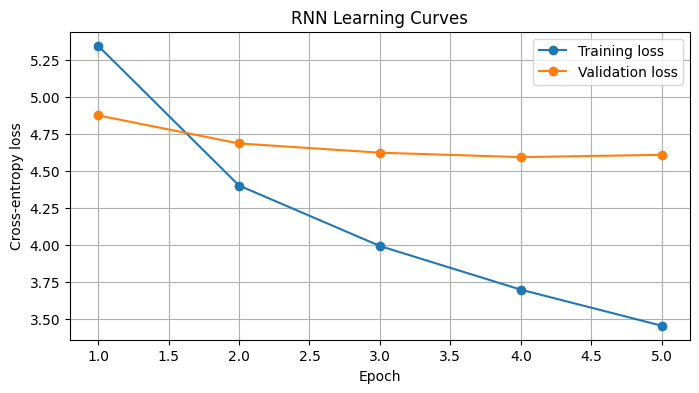

In [ ]:

epochs = range(1, len(rnn_history["train_loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, rnn_history["train_loss"],
         marker="o", label="Training loss")
plt.plot(epochs, rnn_history["val_loss"],
         marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("RNN Learning Curves")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

rnn_test_metrics = evaluate_model(
    rnn_model, test_loader
)

print("RNN Test Results")
print("----------------")
print(f"Test Loss: {rnn_test_metrics['loss']:.4f}")
print(f"Test Accuracy: "
      f"{rnn_test_metrics['accuracy']:.4f}")
print(f"Test Perplexity: "
      f"{rnn_test_metrics['perplexity']:.2f}")


RNN Test Results
----------------
Test Loss: 4.7847
Test Accuracy: 0.2444
Test Perplexity: 119.67


In [ ]:

# Build the LSTM
lstm_model = NextWordModel(
    vocab_size=vocab_size,
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    model_type="LSTM"
).to(device)

# Build the GRU
gru_model = NextWordModel(
    vocab_size=vocab_size,
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    model_type="GRU"
).to(device)

print("LSTM parameters:",
      sum(p.numel() for p in lstm_model.parameters()
          if p.requires_grad))

print("GRU parameters:",
      sum(p.numel() for p in gru_model.parameters()
          if p.requires_grad))


LSTM parameters: 724995
GRU parameters: 691971


In [ ]:

lstm_history = train_model(
    model=lstm_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    learning_rate=0.001
)


Epoch 1/5 | Train Loss: 5.4628 | Val Loss: 5.0129 | Val Accuracy: 0.2099 | Val PPL: 150.34 | Time: 1.6s
Epoch 2/5 | Train Loss: 4.5768 | Val Loss: 4.7606 | Val Accuracy: 0.2311 | Val PPL: 116.82 | Time: 1.5s
Epoch 3/5 | Train Loss: 4.1786 | Val Loss: 4.6506 | Val Accuracy: 0.2404 | Val PPL: 104.65 | Time: 1.5s
Epoch 4/5 | Train Loss: 3.8688 | Val Loss: 4.5984 | Val Accuracy: 0.2543 | Val PPL: 99.33 | Time: 1.4s
Epoch 5/5 | Train Loss: 3.6011 | Val Loss: 4.5957 | Val Accuracy: 0.2523 | Val PPL: 99.06 | Time: 1.4s


In [ ]:

gru_history = train_model(
    model=gru_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    learning_rate=0.001
)


Epoch 1/5 | Train Loss: 5.3330 | Val Loss: 4.8254 | Val Accuracy: 0.2161 | Val PPL: 124.64 | Time: 1.6s
Epoch 2/5 | Train Loss: 4.3411 | Val Loss: 4.5838 | Val Accuracy: 0.2356 | Val PPL: 97.89 | Time: 1.5s
Epoch 3/5 | Train Loss: 3.9005 | Val Loss: 4.5179 | Val Accuracy: 0.2543 | Val PPL: 91.64 | Time: 1.6s
Epoch 4/5 | Train Loss: 3.5709 | Val Loss: 4.5090 | Val Accuracy: 0.2546 | Val PPL: 90.83 | Time: 1.4s
Epoch 5/5 | Train Loss: 3.2892 | Val Loss: 4.5266 | Val Accuracy: 0.2563 | Val PPL: 92.45 | Time: 1.4s


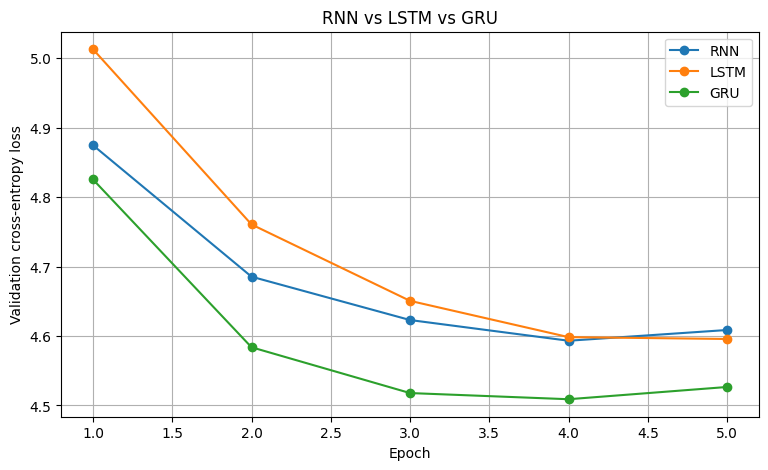

In [ ]:

histories = {
    "RNN": rnn_history,
    "LSTM": lstm_history,
    "GRU": gru_history
}

plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(
        range(1, len(history["val_loss"]) + 1),
        history["val_loss"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("RNN vs LSTM vs GRU")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

models = {
    "RNN": rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

results = []

for name, model in models.items():
    metrics = evaluate_model(model, test_loader)

    results.append({
        "Model": name,
        "Test Loss": metrics["loss"],
        "Test Accuracy": metrics["accuracy"],
        "Test Perplexity": metrics["perplexity"],
        "Parameters": sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))


Model  Test Loss  Test Accuracy  Test Perplexity  Parameters
  RNN     4.7847         0.2444         119.6704      625923
 LSTM     4.7738         0.2484         118.3642      724995
  GRU     4.6999         0.2560         109.9352      691971


In [ ]:

def predict_next_words(
    model,
    prompt,
    num_words=1,
    temperature=1.0
):
    model.eval()

    prompt_tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]",
        prompt.lower()
    )

    if not prompt_tokens:
        raise ValueError("Please enter a non-empty prompt.")

    generated_tokens = prompt_tokens.copy()

    for _ in range(num_words):
        context_tokens = generated_tokens[-SEQ_LEN:]
        context_ids = encode_tokens(context_tokens, vocab)

        x = torch.tensor(
            [context_ids], dtype=torch.long, device=device
        )

        with torch.no_grad():
            logits = model(x)[0]

            if temperature <= 0:
                raise ValueError("Temperature must be positive.")

            probabilities = torch.softmax(
                logits / temperature, dim=-1
            )
            if temperature < 0.01:
                next_id = torch.argmax(probabilities).item()
            else:
                next_id = torch.multinomial(
                    probabilities, num_samples=1
                ).item()

        next_token = id_to_word[next_id]

        if next_token in (PAD_TOKEN, UNK_TOKEN):
            break

        generated_tokens.append(next_token)

    return " ".join(generated_tokens)


prompt = "alice was"
print("RNN:", predict_next_words(
    rnn_model, prompt, num_words=10, temperature=0.01
))
print("LSTM:", predict_next_words(
    lstm_model, prompt, num_words=10, temperature=0.01
))
print("GRU:", predict_next_words(
    gru_model, prompt, num_words=10, temperature=0.01
))


RNN: alice was not like to be a little golden key , and
LSTM: alice was not a little door , and she went on to
GRU: alice was going to be sure to be sure , and she


In [22]:

import os
import json
import torch

PROJECT_DIR = "/content/next_word_prediction"
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)


Project directory: /content/next_word_prediction


In [23]:

model_config = {
    "vocab_size": vocab_size,
    "embed_dim": EMBED_DIM,
    "hidden_dim": HIDDEN_DIM,
    "seq_len": SEQ_LEN,
    "model_types": ["RNN", "LSTM", "GRU"],
    "dataset": "Alice's Adventures in Wonderland",
    "tokenization": "word-level regex tokenizer"
}

for name, model in models.items():
    path = os.path.join(
        PROJECT_DIR, f"{name.lower()}_model.pt"
    )
    torch.save(model.state_dict(), path)
    print("Saved:", path)

with open(
    os.path.join(PROJECT_DIR, "vocabulary.json"), "w"
) as f:
    json.dump(vocab, f, ensure_ascii=False)

with open(
    os.path.join(PROJECT_DIR, "config.json"), "w"
) as f:
    json.dump(model_config, f, indent=2)

print("Vocabulary and configuration saved.")


Saved: /content/next_word_prediction/rnn_model.pt
Saved: /content/next_word_prediction/lstm_model.pt
Saved: /content/next_word_prediction/gru_model.pt
Vocabulary and configuration saved.


In [24]:

results_df.to_csv(
    os.path.join(PROJECT_DIR, "model_comparison.csv"),
    index=False
)

history_data = {
    name: history for name, history in histories.items()
}

with open(
    os.path.join(PROJECT_DIR, "training_history.json"), "w"
) as f:
    json.dump(history_data, f, indent=2)

print(results_df.round(4))
print("\nResults and training histories saved.")


  Model  Test Loss  Test Accuracy  Test Perplexity  Parameters
0   RNN     4.7847         0.2444         119.6704      625923
1  LSTM     4.7738         0.2484         118.3642      724995
2   GRU     4.6999         0.2560         109.9352      691971

Results and training histories saved.


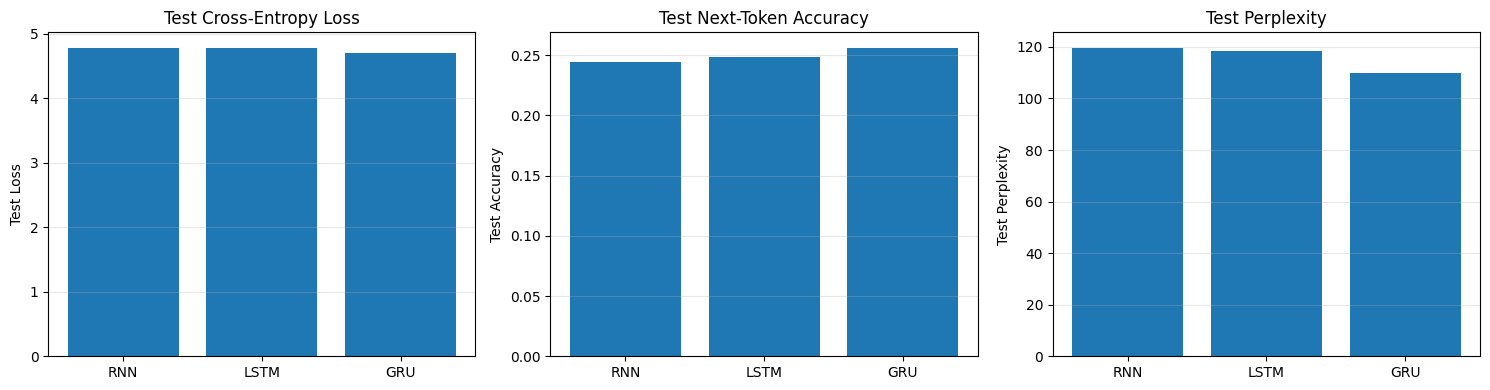

Saved comparison chart: /content/next_word_prediction/model_comparison.png


In [25]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics_to_plot = [
    ("Test Loss", "Test Cross-Entropy Loss"),
    ("Test Accuracy", "Test Next-Token Accuracy"),
    ("Test Perplexity", "Test Perplexity")
]

for ax, (column, title) in zip(axes, metrics_to_plot):
    ax.bar(results_df["Model"], results_df[column])
    ax.set_title(title)
    ax.set_ylabel(column)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

chart_path = os.path.join(
    PROJECT_DIR, "model_comparison.png"
)
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved comparison chart:", chart_path)
